# 05 · Attention — where does the LSTM look, and does that explain its predictions?

Logic: `src/models/lstm_rul.py` (Bahdanau attention), `src/train_lstm.py` (heatmap). Background: EXPERIMENTS E4, E7.

**What attention does here:** the LSTM reads the 30-cycle window one cycle at a time and produces a summary vector after
each cycle (30 vectors). Attention learns 30 weights (≥ 0, summing to 1) — one per **cycle**, not per sensor — and blends
the 30 summaries with them before the final prediction. So the weights show which moments of the window the model leans
on. It is the same idea as attention in language models (there over words), but a single, simple attention step, with
no encoder–decoder and nothing generated.

**Two variants:** bidirectional (a second LSTM also reads the window backwards) and unidirectional (forward only, so it
also works on a live stream).

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import config
from src.plotting import apply_style, save_fig
apply_style()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "results"
from src.models.loader import load_bundle
from src.registry import get_latest
from src.train_lstm import plot_attention
from src.train_sequence import build_seq_inputs
from src.plotting import TEXT_SECONDARY, BLUE, ORANGE, model_style
d, train, (X_val, y_val, u_val), (X_test, test_units) = build_seq_inputs("FD001")
LSTMS = ["lstm_bi", "lstm_bi_tuned", "lstm_uni", "lstm_uni_tuned"]
models = {n: load_bundle(get_latest(n)["path"])[0] for n in LSTMS}
pd.DataFrame({n: m.arch for n, m in models.items()}).T

,hidden_size,num_layers,dropout,bidirectional,attn_dim
lstm_bi,64,1,0.2,True,64
lstm_bi_tuned,256,2,0.339303,True,64
lstm_uni,64,1,0.2,False,64
lstm_uni_tuned,128,3,0.33916,False,64


## 1 · Attention heatmaps over one engine's life
> **How to read this figure:** each ROW is one moment in the life of the longest-lived validation engine (top = 150
> cycles before failure, bottom = at failure); each COLUMN is one cycle inside that moment's 30-cycle window (right =
> newest). Darker = more weight. **Each figure has its own colour scale** — read the colour bar; the black line on it is
> uniform attention (1/30 = 0.033).

**What it tells us:** the 1-layer `lstm_bi` concentrates on the newest cycles. The tuned 3-layer `lstm_uni_tuned`
is close to uniform (peak ≈ 1.8× uniform): it mostly averages the window.

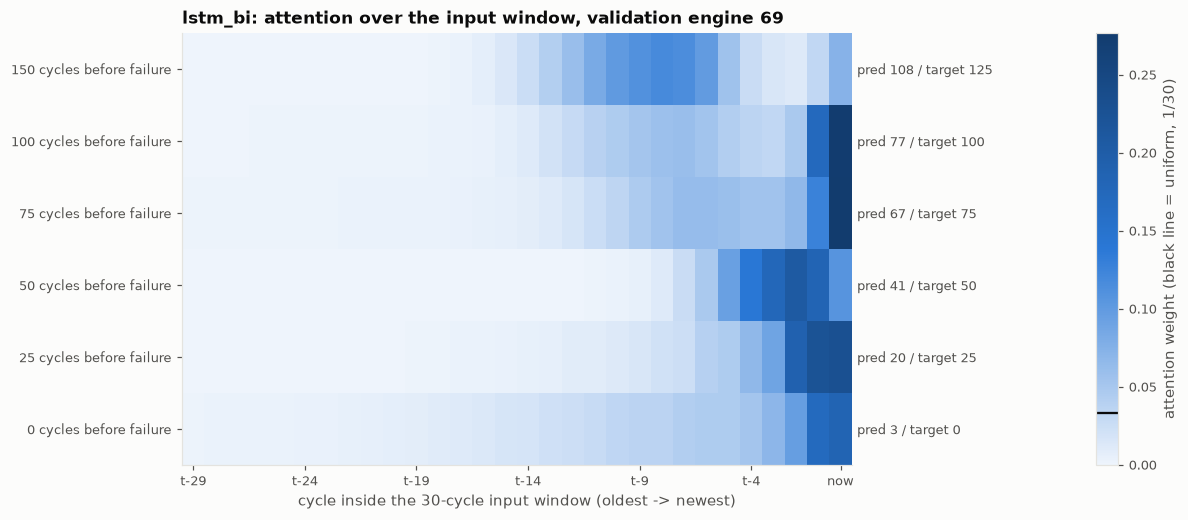

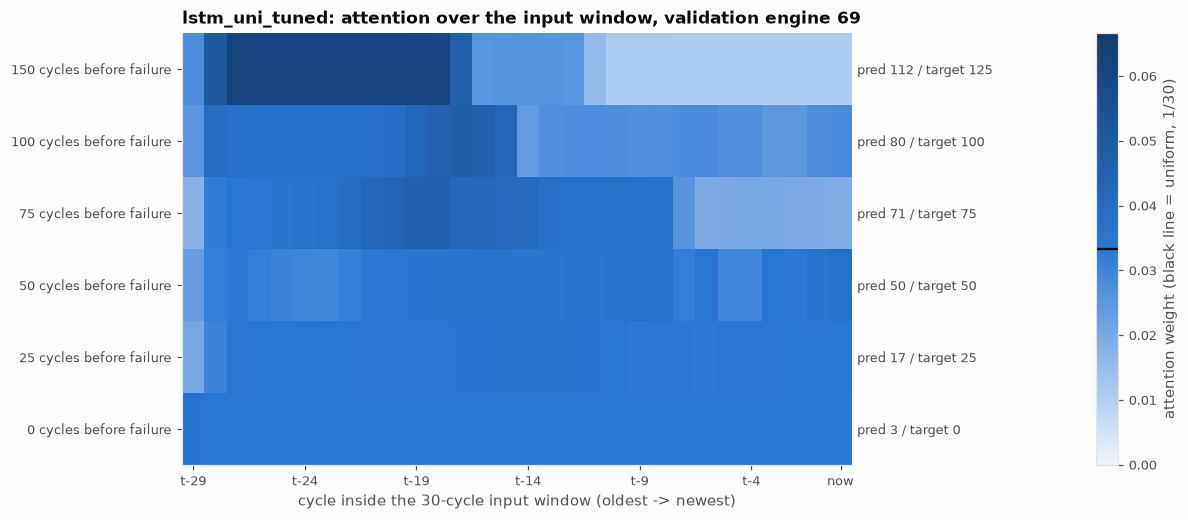

In [2]:
for n in ["lstm_bi", "lstm_uni_tuned"]:
    plot_attention(models[n], d, X_val, u_val, n)
    plt.show()

## 2 · Average attention per window position, all four LSTMs
Averaged over the 100 test windows. The dashed line is uniform attention.

> **How to read this figure:** x = position in the window (30 = newest); y = average attention weight. A curve rising to
> the right = the model leans on recent cycles; a flat curve on the dashed line = it averages the window.

**What it tells us (measured on the 100 test windows):**
- the two **small default models focus on recent cycles**: `lstm_uni` puts 68 % of its weight on the newest 5 cycles
  (peak 13× uniform), `lstm_bi` 37 %;
- the **tuned models barely use attention**: `lstm_uni_tuned` is close to uniform and even leans slightly toward the
  *oldest* cycles; `lstm_bi_tuned` is **exactly uniform** (every weight = 1/30), i.e. its attention does nothing and it
  predicts from the LSTM states alone. Bigger, deeper LSTMs already summarise the window in their states.

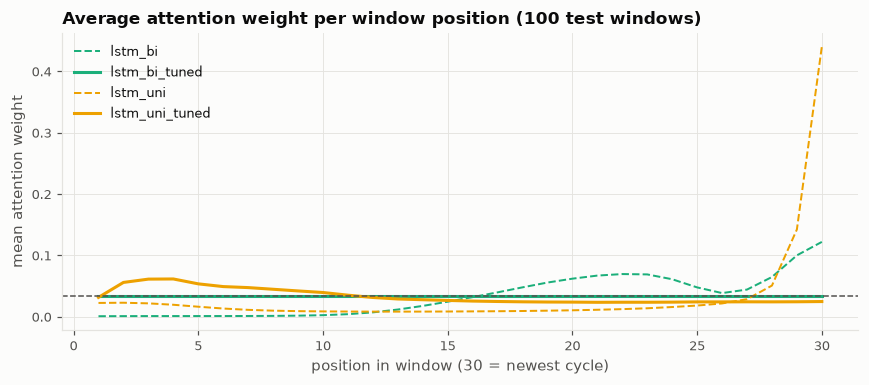

,weight on newest 5 cycles,max / uniform
lstm_bi,0.370,3.659
lstm_bi_tuned,0.167,1.000
lstm_uni,0.684,13.209
lstm_uni_tuned,0.122,1.847


In [3]:
prof = {n: m.attention_weights(X_test).mean(axis=0) for n, m in models.items()}
x = np.arange(1, config.SEQ_LEN + 1)
fig, ax = plt.subplots(figsize=(8, 3.6))
for n, p in prof.items():
    ax.plot(x, p, label=n, **model_style(n))
ax.axhline(1 / config.SEQ_LEN, color=TEXT_SECONDARY, lw=1, ls="--")
ax.set(title="Average attention weight per window position (100 test windows)",
       xlabel="position in window (30 = newest cycle)", ylabel="mean attention weight")
ax.legend(); fig.tight_layout(); save_fig(fig, "attention_profiles"); plt.show()
pd.DataFrame({n: {"weight on newest 5 cycles": p[-5:].sum(), "max / uniform": p.max() * config.SEQ_LEN}
              for n, p in prof.items()}).T.round(3)

## 3 · Attention vs SHAP for `lstm_uni_tuned`
Attention says where the model *looks*; SHAP measures how much each cycle actually *changed the prediction*. Both are
turned into a share per window position (summing to 1) on the same 100 test windows. SHAP here uses 200 samples
(~30 s; notebook 04's analysis used 1,000 — the profile is stable).

> **How to read this figure:** two curves over the window positions. If attention explained the predictions, they
> would have the same shape.

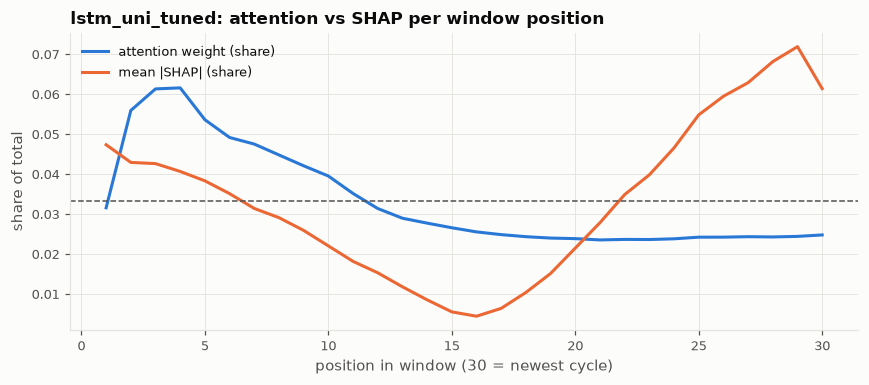

newest 8 cycles: attention 0.19 of the total, SHAP 0.46 (uniform would be 0.27)


In [4]:
from src.explain import gradient_shap
X_tr = train[0]
bg = X_tr[np.random.default_rng(config.SEED).choice(len(X_tr), 200, replace=False)]
m = models["lstm_uni_tuned"]
vals = gradient_shap(m, bg, X_test, nsamples=200, seed=config.SEED)
shap_prof = np.abs(vals).sum(axis=2).mean(axis=0); shap_prof /= shap_prof.sum()
attn_prof = prof["lstm_uni_tuned"] / prof["lstm_uni_tuned"].sum()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(x, attn_prof, color=BLUE, label="attention weight (share)")
ax.plot(x, shap_prof, color=ORANGE, label="mean |SHAP| (share)")
ax.axhline(1 / config.SEQ_LEN, color=TEXT_SECONDARY, lw=1, ls="--")
ax.set(title="lstm_uni_tuned: attention vs SHAP per window position", xlabel="position in window (30 = newest cycle)",
       ylabel="share of total"); ax.legend(); fig.tight_layout(); save_fig(fig, "attention_vs_shap"); plt.show()
print(f"newest 8 cycles: attention {attn_prof[-8:].sum():.2f} of the total, SHAP {shap_prof[-8:].sum():.2f} "
      f"(uniform would be {8 / config.SEQ_LEN:.2f})")

**What it tells us:** the two curves point in almost opposite directions. Attention leans toward the *oldest* cycles
and gives the newest 8 cycles only 19 % of its weight — less than uniform (27 %). SHAP says those same newest 8 cycles
carry **46 %** of the effect on the prediction, with a smaller bump at the window's start (the starting level the
recent change is measured against). The model's dependence on recent cycles lives in the LSTM's states, not in the
attention weights. **Attention shows where a model looks, not what changes its answer** — a known caveat, here
measured (EXPERIMENTS E10).